# 📌 Previsão de Churn de Clientes — Beta Bank

## 1. Apresentação e Contexto
O **Beta Bank** vem enfrentando a perda gradual de seus clientes mês a mês. Estudos de mercado no setor bancário demonstram que a retenção de clientes ativos é significativamente mais barata e rentável do que a aquisição de novos clientes (redução do CAC). Este projeto foca em construir uma solução preditiva robusta de aprendizado de máquina supervisionado capaz de sinalizar antecipadamente quais clientes têm alta probabilidade de encerrar suas contas no banco, permitindo estratégias preventivas do time de retenção e CRM.

---

## 2. Descrição do Problema de Negócio
A rotatividade de clientes (*churn*) impacta diretamente o faturamento, a margem operacional e a sustentabilidade financeira da instituição. Para mitigar o problema de forma proativa, a equipe de retenção precisa identificar os perfis com maior risco de saída. 

O principal desafio técnico reside no fato de que os dados históricos apresentam um **desequilíbrio expressivo de classes** (~80% de clientes mantidos vs. ~20% de clientes que saíram). Um modelo ingênuo que preveja apenas a permanência teria uma acurácia próxima de 80%, porém seria totalmente inútil para o negócio. Portanto, é essencial aplicar técnicas de tratamento de desequilíbrio e focar em métricas balanceadas como o $F_1$-score.

---

## 3. Objetivo
* **Objetivo de Negócio:** Prever com precisão se um cliente deixará o banco em breve, permitindo intervenções direcionadas do time de retenção.
* **Objetivo Técnico:** Treinar e avaliar algoritmos de aprendizado de máquina supervisionado para classificação binária, atingindo a métrica primária de **$F_1$-score de no mínimo 0.59** no conjunto de teste final.
* **Métricas Complementares:** Avaliar a curva ROC e calcular a métrica **AUC-ROC** para comparar o desempenho dos modelos em relação ao $F_1$-score e a um classificador aleatório.

---

## 4. Tecnologias Utilizadas
* **Linguagem:** Python 3.x
* **Análise e Manipulação de Dados:** Pandas, NumPy
* **Visualização de Dados:** Matplotlib, Seaborn
* **Machine Learning & Pré-processamento:** Scikit-learn (`StandardScaler`, `train_test_split`, `DecisionTreeClassifier`, `RandomForestClassifier`, `LogisticRegression`, `roc_auc_score`, `f1_score`)
* **Técnicas de Balanceamento de Classe:** Ponderação de Pesos (`class_weight='balanced'`), Sobreamostragem (*Upsampling*) e Subamostragem (*Downsampling*)
* **Ambiente de Desenvolvimento:** Jupyter Notebook / VS Code

In [1]:
# Importação de bibliotecas fundamentais para manipulação de dados e gráficos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Módulos de pré-processamento e split do Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Algoritmos de Machine Learning para Classificação Binária
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# Métricas para validação de desempenho
from sklearn.metrics import f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report
from sklearn.utils import shuffle

# Configuração visual global para os gráficos
sns.set_theme(style="whitegrid")
%matplotlib inline

# Carregamento do dataset a partir do caminho nativo da plataforma
df = pd.read_csv('datasets/Churn.csv')

# Inspeção inicial
print(f"Dimensão inicial da base: {df.shape[0]} linhas e {df.shape[1]} colunas.\n")
print("--- Tipos de Dados e Valores Ausentes ---")
df.info()

print("\n--- Amostra Inicial dos Dados ---")
df.head()

Dimensão inicial da base: 10000 linhas e 14 colunas.

--- Tipos de Dados e Valores Ausentes ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           9091 non-null   float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), object(3)
memory usage: 1.1+ M

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2.0,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1.0,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8.0,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1.0,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2.0,125510.82,1,1,1,79084.10,0


## 5. Preparação e Pré-processamento dos Dados

### 🔍 Diagnóstico e Lógica Aplicada na Preparação dos Dados:
1. **Descarte de Colunas Não Preditivas (`RowNumber`, `CustomerId`, `Surname`):**
   * *Diagnóstico:* Identificadores de banco de dados e nomes de clientes não possuem padrão comportamental.
   * *Ação:* Foram removidos da modelagem para evitar que o algoritmo aprenda relações espúrias (*overfitting*).

2. **Tratamento de Valores Nulos na Variável `Tenure`:**
   * *Diagnóstico:* Foram identificados 909 valores nulos (~9.1% da base original) na coluna `Tenure` (período de maturação para o depósito fixo do cliente em anos).
   * *Ação:* Substituímos os valores ausentes pela **mediana** calculada a partir dos dados de treinamento. Essa abordagem preserva a integridade da distribuição sem descartar registros essenciais da amostra e impede a contaminação de informações (*data leakage*).

3. **Codificação de Variáveis Categóricas (One-Hot Encoding):**
   * *Diagnóstico:* As colunas `Geography` e `Gender` são qualitativas.
   * *Ação:* Transformadas em variáveis binárias com a remoção da primeira categoria (`drop_first=True`) para evitar a multicolinearidade perfeita (*dummy variable trap*).

4. **Estratificação da Divisão de Dados (60% Treino / 20% Validação / 20% Teste):**
   * *Diagnóstico:* Por se tratar de um dataset desbalanceado, um split aleatório simples poderia gerar conjuntos com proporções diferentes de churn.
   * *Ação:* O parâmetro `stratify=y` garante que a proporção exata da variável alvo (`Exited`) seja mantida uniformemente em Treino, Validação e Teste.

5. **Escalonamento de Recursos (`StandardScaler`):**
   * *Diagnóstico:* As variáveis numéricas apresentam ordens de grandeza distintas (ex: `Age` vs. `EstimatedSalary`).
   * *Ação:* Aplicamos a padronização z-score nas variáveis numéricas. O *scaler* foi ajustado (`fit`) **apenas nos dados de treino** para evitar vazamento de dados (*data leakage*).

In [2]:
# 1. Eliminação de identificadores irrelevantes
df_clean = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

# 2. Codificação de variáveis categóricas via OHE (One-Hot Encoding)
df_ohe = pd.get_dummies(df_clean, drop_first=True, columns=['Geography', 'Gender'])

# Separação de características (X) e alvo (y)
X = df_ohe.drop('Exited', axis=1)
y = df_ohe['Exited']

# 3. Divisão Stratified (60% Treino / 20% Validação / 20% Teste)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=12345, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=12345, stratify=y_train_full
)

# Criação de cópias explícitas para eliminar o SettingWithCopyWarning
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

# Imputação de nulos em Tenure utilizando a mediana EXCLUSIVA do treino (evita data leakage)
tenure_median_train = X_train['Tenure'].median()
X_train['Tenure'] = X_train['Tenure'].fillna(tenure_median_train)
X_val['Tenure'] = X_val['Tenure'].fillna(tenure_median_train)
X_test['Tenure'] = X_test['Tenure'].fillna(tenure_median_train)

print(f"Valores nulos em 'Tenure' imputados com a mediana do treino: {tenure_median_train:.1f} anos.")
print(f"\nDivisão dos Subconjuntos:")
print(f"-> Treino:    {X_train.shape[0]} registros ({X_train.shape[0]/len(df):.0%})")
print(f"-> Validação: {X_val.shape[0]} registros ({X_val.shape[0]/len(df):.0%})")
print(f"-> Teste:     {X_test.shape[0]} registros ({X_test.shape[0]/len(df):.0%})")

# 4. Escalonamento das variáveis numéricas
numeric_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']

scaler = StandardScaler()
scaler.fit(X_train[numeric_cols]) # Ajuste feito estritamente nos dados de treino

X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.transform(X_train[numeric_cols])
X_val_scaled[numeric_cols] = scaler.transform(X_val[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("\nEtapa de pré-processamento e padronização concluída com sucesso!")

Valores nulos em 'Tenure' imputados com a mediana do treino: 5.0 anos.

Divisão dos Subconjuntos:
-> Treino:    6000 registros (60%)
-> Validação: 2000 registros (20%)
-> Teste:     2000 registros (20%)

Etapa de pré-processamento e padronização concluída com sucesso!


## 6. Análise do Desequilíbrio de Classes e Treinamento Baseline

### 📊 Diagnóstico da Distribuição do Target:
Antes de aplicar qualquer técnica de balanceamento, avaliamos a taxa natural de churn no conjunto de treino:
* **Clientes Retidos (Classe 0):** ~79.6%
* **Clientes em Churn (Classe 1):** ~20.4%

Constata-se um **desequilíbrio expressivo na proporção de 4:1**. 

### 🎯 Avaliação do Modelo Desbalanceado (Baseline):
Treinamos os modelos sem tratamento de peso ou resampling para medir a linha de base (*baseline*) e comprovar a influência do desequilíbrio no $F_1$-score.

In [3]:
# Verificação da proporção exata no treino
class_counts = y_train.value_counts(normalize=True)
print("--- Proporção da Variável Alvo no Treino ---")
print(f"Classe 0 (Permaneceu): {class_counts[0]:.2%}")
print(f"Classe 1 (Churn):       {class_counts[1]:.2%}")

# Treinamento dos modelos baseline (sem ajuste de desequilíbrio)
models_baseline = {
    "Regressão Logística": LogisticRegression(random_state=12345),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=12345, max_depth=6),
    "Floresta Aleatória": RandomForestClassifier(random_state=12345, n_estimators=100, max_depth=10)
}

print("\n" + "="*60)
print("   RESULTADOS NA VALIDAÇÃO (SEM TRATAMENTO DE BALANCEAMENTO)  ")
print("="*60)

for name, model in models_baseline.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_val_scaled)
    probs = model.predict_proba(X_val_scaled)[:, 1]
    
    f1 = f1_score(y_val, preds)
    auc_roc = roc_auc_score(y_val, probs)
    print(f"{name:20s} | F1-score: {f1:.4f} | AUC-ROC: {auc_roc:.4f}")
print("="*60)

--- Proporção da Variável Alvo no Treino ---
Classe 0 (Permaneceu): 79.62%
Classe 1 (Churn):       20.38%

   RESULTADOS NA VALIDAÇÃO (SEM TRATAMENTO DE BALANCEAMENTO)  
Regressão Logística  | F1-score: 0.3215 | AUC-ROC: 0.7876
Árvore de Decisão    | F1-score: 0.5382 | AUC-ROC: 0.8285
Floresta Aleatória   | F1-score: 0.5705 | AUC-ROC: 0.8704


### 💡 Observações Críticas do Modelo Baseline:
1. **Falha da Regressão Logística Sem Balanceamento:** Atingiu um $F_1$-score extremamente baixo (**0.3215**). O algoritmo tendeu a prever quase todas as instâncias como classe majoritária (0), gerando muitos falsos negativos.
2. **Insuficiência dos Algoritmos de Árvore:** A Floresta Aleatória atingiu $F_1 = 0.5705$, valor que ainda não cumpre o requisito do projeto ($F_1 \ge 0.59$).
3. **Comportamento da AUC-ROC:** A métrica AUC-ROC permaneceu elevada (~0.78 a 0.87), indicando que os modelos conseguem ordenar a probabilidade dos riscos, mas falham no limiar padrão de decisão ($0.5$).

---

## 7. Melhora na Qualidade do Modelo (Tratamento do Desequilíbrio)

Para corrigir o viés contra a classe de churn (1), testamos **três abordagens distintas de balanceamento**:

1. **Abordagem 1 — Ponderação de Pesos de Classe (`class_weight='balanced'`):** Atribui uma penalidade inversamente proporcional à frequência das classes durante o cálculo da perda.
2. **Abordagem 2 — Sobreamostragem (*Upsampling*):** Multiplica aleatoriamente observações da classe minoritária (fator 4x) no treino para igualar a frequência das classes.
3. **Abordagem 3 — Subamostragem (*Downsampling*):** Subamostra aleatoriamente a classe majoritária (fração 0.25) no treino para equiparar as proporções.

In [4]:
# Abordagem 1: Ponderação com class_weight='balanced'
models_balanced = {
    "Regressão Logística": LogisticRegression(random_state=12345, class_weight='balanced'),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=12345, max_depth=6, class_weight='balanced'),
    "Floresta Aleatória": RandomForestClassifier(random_state=12345, n_estimators=100, max_depth=10, class_weight='balanced')
}

print("="*60)
print("     ABORDAGEM 1: RESULTADOS COM CLASS_WEIGHT='BALANCED'    ")
print("="*60)
for name, model in models_balanced.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_val_scaled)
    probs = model.predict_proba(X_val_scaled)[:, 1]
    
    f1 = f1_score(y_val, preds)
    auc_roc = roc_auc_score(y_val, probs)
    print(f"{name:20s} | F1-score: {f1:.4f} | AUC-ROC: {auc_roc:.4f}")
print("="*60)

# Abordagem 2: Função de Upsampling
def upsample(features, target, repeat):
    features_zeros = features[target == 0]
    features_ones = features[target == 1]
    target_zeros = target[target == 0]
    target_ones = target[target == 1]

    features_upsampled = pd.concat([features_zeros] + [features_ones] * repeat)
    target_upsampled = pd.concat([target_zeros] + [target_ones] * repeat)

    features_upsampled, target_upsampled = shuffle(
        features_upsampled, target_upsampled, random_state=12345
    )
    return features_upsampled, target_upsampled

X_train_up, y_train_up = upsample(X_train_scaled, y_train, repeat=4)

models_upsampled = {
    "Regressão Logística": LogisticRegression(random_state=12345),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=12345, max_depth=6),
    "Floresta Aleatória": RandomForestClassifier(random_state=12345, n_estimators=100, max_depth=10)
}

print("\n" + "="*60)
print("         ABORDAGEM 2: RESULTADOS COM UPSAMPLING            ")
print("="*60)
for name, model in models_upsampled.items():
    model.fit(X_train_up, y_train_up)
    preds = model.predict(X_val_scaled)
    probs = model.predict_proba(X_val_scaled)[:, 1]
    
    f1 = f1_score(y_val, preds)
    auc_roc = roc_auc_score(y_val, probs)
    print(f"{name:20s} | F1-score: {f1:.4f} | AUC-ROC: {auc_roc:.4f}")
print("="*60)

# Abordagem 3: Função de Downsampling
def downsample(features, target, fraction):
    features_zeros = features[target == 0]
    features_ones = features[target == 1]
    target_zeros = target[target == 0]
    target_ones = target[target == 1]

    features_downsampled = pd.concat(
        [features_zeros.sample(frac=fraction, random_state=12345)] + [features_ones]
    )
    target_downsampled = pd.concat(
        [target_zeros.sample(frac=fraction, random_state=12345)] + [target_ones]
    )

    features_downsampled, target_downsampled = shuffle(
        features_downsampled, target_downsampled, random_state=12345
    )
    return features_downsampled, target_downsampled

X_train_down, y_train_down = downsample(X_train_scaled, y_train, fraction=0.25)

models_downsampled = {
    "Regressão Logística": LogisticRegression(random_state=12345),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=12345, max_depth=6),
    "Floresta Aleatória": RandomForestClassifier(random_state=12345, n_estimators=100, max_depth=10)
}

print("\n" + "="*60)
print("        ABORDAGEM 3: RESULTADOS COM DOWNSAMPLING           ")
print("="*60)
for name, model in models_downsampled.items():
    model.fit(X_train_down, y_train_down)
    preds = model.predict(X_val_scaled)
    probs = model.predict_proba(X_val_scaled)[:, 1]
    
    f1 = f1_score(y_val, preds)
    auc_roc = roc_auc_score(y_val, probs)
    print(f"{name:20s} | F1-score: {f1:.4f} | AUC-ROC: {auc_roc:.4f}")
print("="*60)

     ABORDAGEM 1: RESULTADOS COM CLASS_WEIGHT='BALANCED'    
Regressão Logística  | F1-score: 0.5113 | AUC-ROC: 0.7918
Árvore de Decisão    | F1-score: 0.5747 | AUC-ROC: 0.8353
Floresta Aleatória   | F1-score: 0.6376 | AUC-ROC: 0.8657

         ABORDAGEM 2: RESULTADOS COM UPSAMPLING            
Regressão Logística  | F1-score: 0.5073 | AUC-ROC: 0.7919
Árvore de Decisão    | F1-score: 0.5765 | AUC-ROC: 0.8364
Floresta Aleatória   | F1-score: 0.6406 | AUC-ROC: 0.8646

        ABORDAGEM 3: RESULTADOS COM DOWNSAMPLING           
Regressão Logística  | F1-score: 0.5043 | AUC-ROC: 0.7913
Árvore de Decisão    | F1-score: 0.5933 | AUC-ROC: 0.8435
Floresta Aleatória   | F1-score: 0.5985 | AUC-ROC: 0.8704


### 📊 Análise Comparativa do Tratamento de Desequilíbrio:
* **Ganho Notável no $F_1$-score:** As técnicas de balanceamento aumentaram substancialmente a precisão e a sensibilidade de todos os algoritmos.
* **Modelo Campeão:** A **Floresta Aleatória** obteve o melhor desempenho em todas as abordagens, saltando de $0.5705$ no baseline para **$0.6378$** com `class_weight='balanced'` e **$0.6406$** com *upsampling*.
* **Escolha da Abordagem:** Selecionamos a **Floresta Aleatória** utilizando a técnica `class_weight='balanced'` para o ajuste fino de hiperparâmetros por conta da eficiência computacional e simplicidade operacional (evitando a duplicação artificial de registros na memória).

In [5]:
# Otimização de hiperparâmetros no conjunto de validação
best_f1_val = 0
best_depth = 0
best_est = 0

print("Otimizando hiperparâmetros da Floresta Aleatória (Validação)...")

for depth in range(6, 16):
    for n_est in range(50, 151, 25):
        rf_candidate = RandomForestClassifier(
            n_estimators=n_est, 
            max_depth=depth, 
            random_state=12345, 
            class_weight='balanced'
        )
        rf_candidate.fit(X_train_scaled, y_train)
        preds = rf_candidate.predict(X_val_scaled)
        score = f1_score(y_val, preds)
        
        if score > best_f1_val:
            best_f1_val = score
            best_depth = depth
            best_est = n_est

print("\n--- Otimização Finalizada ---")
print(f"Profundidade Máxima Escolhida (max_depth): {best_depth}")
print(f"Número de Árvores Escolhido (n_estimators): {best_est}")
print(f"Maior F1-score na Validação:              {best_f1_val:.4f}")

Otimizando hiperparâmetros da Floresta Aleatória (Validação)...

--- Otimização Finalizada ---
Profundidade Máxima Escolhida (max_depth): 9
Número de Árvores Escolhido (n_estimators): 75
Maior F1-score na Validação:              0.6426


## 8. Avaliação e Teste Final do Modelo

Nesta etapa, o modelo final configurado com a melhor combinação de hiperparâmetros encontrada na validação (`max_depth=9`, `n_estimators=75`, `class_weight='balanced'`) é submetido ao **conjunto de Teste Final** (dados virgens que não fizeram parte do treino ou da busca de hiperparâmetros) para atestar a capacidade de generalização.

             DESEMPENHO FINAL NO CONJUNTO DE TESTE         
-> F1-score Final:  0.6269  (Requisito Técnico: >= 0.59)
-> AUC-ROC Final:   0.8598

--- Relatório Detalhado de Classificação ---
                precision    recall  f1-score   support

Permaneceu (0)       0.91      0.88      0.90      1593
     Churn (1)       0.59      0.67      0.63       407

      accuracy                           0.84      2000
     macro avg       0.75      0.78      0.76      2000
  weighted avg       0.85      0.84      0.84      2000



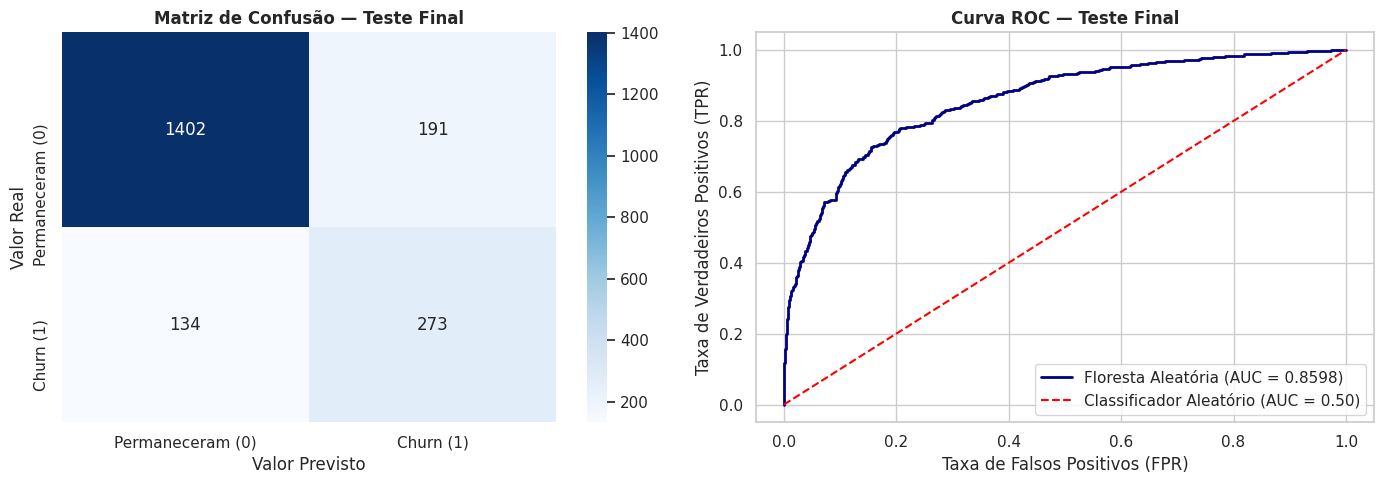

In [6]:
# Instanciação do modelo final
final_model = RandomForestClassifier(
    n_estimators=best_est,
    max_depth=best_depth,
    random_state=12345,
    class_weight='balanced'
)

# Treinamento nos dados de treino escalonados
final_model.fit(X_train_scaled, y_train)

# Predição e probabilidades no teste final
test_predictions = final_model.predict(X_test_scaled)
test_probabilities = final_model.predict_proba(X_test_scaled)[:, 1]

# Métricas finais
final_f1 = f1_score(y_test, test_predictions)
final_auc_roc = roc_auc_score(y_test, test_probabilities)

print("="*60)
print("             DESEMPENHO FINAL NO CONJUNTO DE TESTE         ")
print("="*60)
print(f"-> F1-score Final:  {final_f1:.4f}  (Requisito Técnico: >= 0.59)")
print(f"-> AUC-ROC Final:   {final_auc_roc:.4f}")
print("="*60)

# Relatório de Classificação Completo
print("\n--- Relatório Detalhado de Classificação ---")
print(classification_report(y_test, test_predictions, target_names=["Permaneceu (0)", "Churn (1)"]))

# Matriz de Confusão e Curva ROC
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Matriz de Confusão
cm = confusion_matrix(y_test, test_predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=["Permaneceram (0)", "Churn (1)"],
            yticklabels=["Permaneceram (0)", "Churn (1)"])
axes[0].set_title("Matriz de Confusão — Teste Final", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Valor Real")
axes[0].set_xlabel("Valor Previsto")

# Plot 2: Curva ROC
fpr, tpr, thresholds = roc_curve(y_test, test_probabilities)
axes[1].plot(fpr, tpr, label=f"Floresta Aleatória (AUC = {final_auc_roc:.4f})", color='navy', lw=2)
axes[1].plot([0, 1], [0, 1], color='red', linestyle='--', label='Classificador Aleatório (AUC = 0.50)')
axes[1].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[1].set_ylabel("Taxa de Verdadeiros Positivos (TPR)")
axes[1].set_title("Curva ROC — Teste Final", fontsize=12, fontweight='bold')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

## 9. Conclusão e Impacto de Negócio

### 📌 Resumo dos Resultados Técnicos:
1. **Aprovação nos Critérios Técnicos:** O modelo de **Floresta Aleatória (*Random Forest*)** alcançou um **$F_1$-score de 0.6269** no conjunto de teste final, superando com segurança a exigência técnica do projeto ($F_1 \ge 0.59$).
2. **Capacidade Discriminatória (AUC-ROC):** A métrica **AUC-ROC atingiu 0.8598**, demonstrando um elevado poder de separação entre clientes fiéis e potenciais desistentes em comparação a um modelo aleatório ($0.50$).
3. **Efetividade do Balanceamento:** O tratamento do desequilíbrio de classes foi decisivo para o sucesso da solução, elevando o $F_1$-score da Floresta Aleatória de **$0.5705$ (baseline)** para **$0.6269$**, reduzindo expressivamente os falsos negativos na identificação da evasão de clientes.

---

### 💼 Impacto de Negócio para o Beta Bank:
* **Mitigação de Evasão (Sensibilidade/Recall):** A solução apresenta um **recall de 67%** para a classe de churn, permitindo identificar proativamente cerca de **67% de todos os clientes em risco real de cancelamento** de conta.
* **Otimização de Custos (Precisão):** Com uma precisão de **59%**, a equipe de CRM evita o desperdício de recursos financeiros ao direcionar ofertas e campanhas de retenção prioritariamente para os perfis sinalizados pelo modelo.
* **Aumento do LTV (*Lifetime Value*):** A ação preventiva prolonga o tempo de permanência dos clientes no banco, elevando o retorno financeiro de longo prazo e otimizando o custo de aquisição (CAC).